# Truy hồi (RAG): embedding, chỉ mục và ablation

Đọc `results/embedding_benchmark.json` (số đo so sánh model embedding), `results/night_report.json` (lượt dựng chỉ mục đầy đủ),
`results/ablation.json` và `results/examples.json` (sinh ở bước đánh giá). File chưa có sẽ hiện ô "chưa có".

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

# Gốc dữ liệu: VRE_DATA_ROOT (vre_env.ps1 đặt về checkout chính) hoặc gốc repo (CI, chạy từ notebooks/).
_here = Path.cwd().resolve()
DATA_ROOT = Path(os.environ.get("VRE_DATA_ROOT") or (_here.parent if _here.name == "notebooks" else _here))
RESULTS = DATA_ROOT / "results"
pd.set_option("display.max_colwidth", 120)


def load(name):
    """Đọc results/<name>; trả None nếu file chưa được sinh."""
    path = RESULTS / name
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else None


def md(text):
    display(Markdown(text))


def missing(name, command):
    md(f"> **chưa có** — `results/{name}` chưa được sinh. Sinh bằng `{command}` rồi chạy lại notebook.")


def num(x):
    """Số nguyên kiểu Việt Nam: 2.537.920."""
    return f"{int(x):,}".replace(",", ".")


def dec(x, digits=2):
    """Số thực kiểu Việt Nam: 0,71."""
    return f"{x:,.{digits}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def pct(x, digits=1):
    """Tỉ lệ 0..1 → phần trăm."""
    return dec(x * 100, digits) + "%"


def provenance(obj):
    if isinstance(obj, dict) and "generated_at" in obj:
        md(f"*Nguồn: sinh lúc `{obj['generated_at']}`, commit `{obj.get('git_sha')}`.*")


md("Đọc `results/` dưới " + ("`VRE_DATA_ROOT`." if os.environ.get("VRE_DATA_ROOT") else "gốc repo."))

Đọc `results/` dưới `VRE_DATA_ROOT`.

## Vì sao chọn `multilingual-e5-large`

In [2]:
bench = load("embedding_benchmark.json")
if bench is None:
    missing("embedding_benchmark.json", "python scripts/vre_pipeline.py ingest")
else:
    cols = ["model", "params_m", "dim", "recall_at_1", "recall_at_10", "mrr_at_10", "docs_per_s", "hours_2_8m_chunks",
            "peak_vram_gb", "token_budget"]
    emb = pd.DataFrame(bench)[cols].sort_values("mrr_at_10", ascending=False).reset_index(drop=True)
    display(emb)
    best, fastest = emb.iloc[0], emb.sort_values("docs_per_s", ascending=False).iloc[0]
    q = bench[0]
    md(
        f"Cùng một phép đo ({num(q['corpus'])} tin ngẫu nhiên đã khử trùng, {num(q['queries'])} truy vấn tiêu đề → mô tả, fp16): "
        f"**`{best['model']}`** có MRR@10 cao nhất ({dec(best['mrr_at_10'], 3)}), recall@1 {dec(best['recall_at_1'], 3)}, "
        f"recall@10 {dec(best['recall_at_10'], 3)}. Model nhanh nhất `{fastest['model']}` đạt {dec(fastest['docs_per_s'], 1)} tin/giây "
        f"nhưng MRR@10 chỉ {dec(fastest['mrr_at_10'], 3)}. Với `{best['model']}` ước tính "
        f"{dec(best['hours_2_8m_chunks'], 2)} giờ cho toàn bộ chunk, chấp nhận được cho một lượt chạy qua đêm, "
        f"nên chất lượng truy hồi được ưu tiên hơn tốc độ."
    )

,model,params_m,dim,recall_at_1,recall_at_10,mrr_at_10,docs_per_s,hours_2_8m_chunks,peak_vram_gb,token_budget
0,intfloat/multilingual-e5-large,560,1024,0.656,0.816,0.7110,98.8,7.87,2.00,32768
1,BAAI/bge-m3,568,1024,0.626,0.782,0.6809,120.3,6.47,1.61,16384
2,intfloat/multilingual-e5-small,118,384,0.591,0.769,0.6494,802.3,0.97,0.42,16384
3,intfloat/multilingual-e5-base,278,768,0.589,0.759,0.6429,429.6,1.81,0.92,16384


Cùng một phép đo (20.000 tin ngẫu nhiên đã khử trùng, 1.000 truy vấn tiêu đề → mô tả, fp16): **`intfloat/multilingual-e5-large`** có MRR@10 cao nhất (0,711), recall@1 0,656, recall@10 0,816. Model nhanh nhất `intfloat/multilingual-e5-small` đạt 802,3 tin/giây nhưng MRR@10 chỉ 0,649. Với `intfloat/multilingual-e5-large` ước tính 7,87 giờ cho toàn bộ chunk, chấp nhận được cho một lượt chạy qua đêm, nên chất lượng truy hồi được ưu tiên hơn tốc độ.

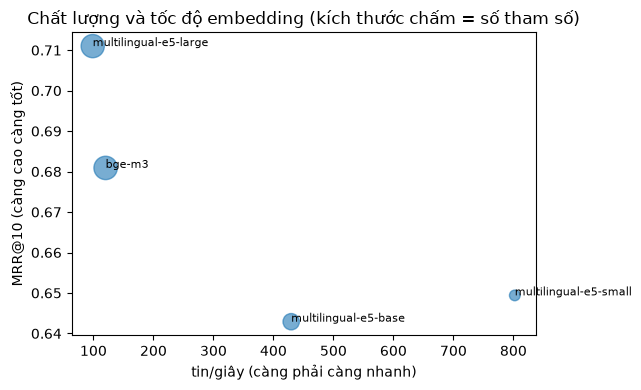

Thông lượng (tin/giây) theo ngân sách token mỗi lô:

,BAAI/bge-m3,intfloat/multilingual-e5-large,intfloat/multilingual-e5-base,intfloat/multilingual-e5-small
token_budget,,,,
16384,162.2,102.0,426.5,726.1
32768,139.6,104.3,420.0,690.3
65536,127.9,97.5,399.4,678.3
131072,111.4,99.4,361.2,626.8


In [3]:
if bench is not None:
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.scatter(emb["docs_per_s"], emb["mrr_at_10"], s=emb["params_m"] / 2, alpha=0.6)
    for _, r in emb.iterrows():
        ax.annotate(r["model"].split("/")[-1], (r["docs_per_s"], r["mrr_at_10"]), fontsize=8)
    ax.set_xlabel("tin/giây (càng phải càng nhanh)")
    ax.set_ylabel("MRR@10 (càng cao càng tốt)")
    ax.set_title("Chất lượng và tốc độ embedding (kích thước chấm = số tham số)")
    fig.tight_layout()
    plt.show()
    sweep = pd.DataFrame({m["model"]: {k: v["docs_per_s"] for k, v in m["sweep"].items()} for m in bench})
    sweep.index.name = "token_budget"
    md("Thông lượng (tin/giây) theo ngân sách token mỗi lô:")
    display(sweep)

## Cấu hình embedding cố định

In [4]:
night = load("night_report.json")
if night is None:
    missing("night_report.json", "python scripts/vre_pipeline.py night --resume")
else:
    md(
        f"Chỉ mục dùng model `{night['model_slug']}`, collection `{night['collection']}`, "
        f"ngân sách token mỗi lô `{night['embed']['token_budget']}` (lấy từ số đo trên, không đo lại)."
    )

Chỉ mục dùng model `e5_large`, collection `vre_chunks_e5_large`, ngân sách token mỗi lô `32768` (lấy từ số đo trên, không đo lại).

## Lượt dựng chỉ mục đầy đủ

*Nguồn: sinh lúc `2026-10-15T13:28:50Z`, commit `dirty`.*

Trạng thái **completed**: bắt đầu `2026-10-15T02:06:13Z`, xong `2026-10-15T13:20:47Z`, tổng 11,24 giờ chạy qua 1 lần resume. 2.685.246 chunk từ 51 phần; Qdrant `green` với 2.685.246 point và 5.373.052 vector đã đánh chỉ mục. Tốc độ embed trung bình 100,9 chunk/giây; BM25 avgdl 117,28.

,name,status,seconds,items_done,items_total,note
0,checks,done,1.8,0,0,vre.checks.require (CLI) + fingerprint/state
1,chunk,done,0.0,0,51,NaN
2,bm25,done,0.0,0,51,avgdl=117.28
3,embed,done,0.0,0,51,NaN
4,upload,done,3758.5,51,51,NaN
5,hnsw,done,887.0,0,0,NaN
6,verify,done,16.3,0,0,"smoke hits {'căn hộ 2 phòng ngủ quận 7 dưới 4 tỷ': 10, 'nhà mặt tiền kinh doanh Hà Nội': 10, 'đất nền sổ đỏ Bình Dươ..."
7,pca,done,188.6,0,51,"2537920 tin, explained_variance=0.407"
8,report,done,0.0,0,0,NaN


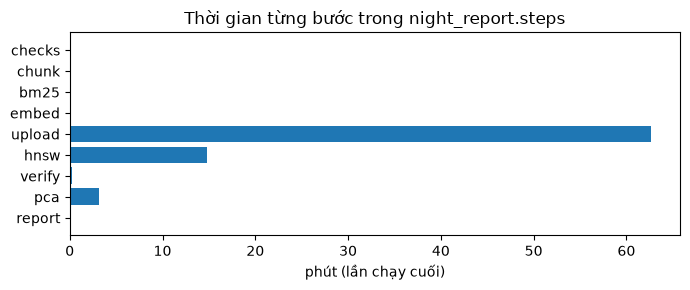

In [5]:
if night is not None:
    provenance(night)
    c, qd = night["counters"], night["qdrant"]
    md(
        f"Trạng thái **{night['status']}**: bắt đầu `{night['started_at']}`, xong `{night['finished_at']}`, tổng "
        f"{dec(night['wall_hours'], 2)} giờ chạy qua {num(night['resumed_runs'])} lần resume. "
        f"{num(c['chunks'])} chunk từ {num(c['parts_total'])} phần; Qdrant `{qd['status']}` với {num(qd['points'])} point "
        f"và {num(qd['indexed_vectors'])} vector đã đánh chỉ mục. Tốc độ embed trung bình "
        f"{dec(night['embed']['chunks_per_s_avg'], 1)} chunk/giây; BM25 avgdl {dec(night['bm25']['avgdl'], 2)}."
    )
    steps = pd.DataFrame(night["steps"])[["name", "status", "seconds", "items_done", "items_total", "note"]]
    display(steps)
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.barh(steps["name"], steps["seconds"] / 60)
    ax.invert_yaxis()
    ax.set_xlabel("phút (lần chạy cuối)")
    ax.set_title("Thời gian từng bước trong night_report.steps")
    fig.tight_layout()
    plt.show()

In [6]:
if night is not None:
    display(pd.Series(night["counters"], name="counters").to_frame())
    peaks = {k: ("không ghi" if v is None else v) for k, v in night["peaks"].items()}
    display(pd.Series(peaks, name="peaks").to_frame())
    if night["errors"]:
        md("Lỗi / cảnh báo ghi trong báo cáo:")
        display(pd.DataFrame(night["errors"]))
    else:
        md("Không có lỗi hay cảnh báo nào được ghi.")

,counters
parts_total,51
parts_embedded,51
parts_uploaded,51
chunks,2685246
points_in_qdrant,2685246
chunks_truncated_listings,0
oom_retries,0
upload_retries,0
batch_size_final,0


,peaks
ram_used_gb,không ghi
vram_peak_gb,không ghi


Lỗi / cảnh báo ghi trong báo cáo:

,at,step,part,type,message
0,2026-10-15T13:28:50Z,report,None,warn,run 1 was stopped by hand at 44/51 uploaded (commit memory); its report was never written. embed.chunks_per_s_avg re...


## Ablation truy hồi

In [7]:
abl = load("ablation.json")
if abl is None:
    missing("ablation.json", "python scripts/vre_pipeline.py ablation")
else:
    provenance(abl)
    co = abl["corpus"]
    md(f"Subcorpus {num(co['n_listings'])} tin (chứa {num(co['n_gt_listings'])} tin đáp án), seed `{co['seed']}`.")
    runs = pd.DataFrame(abl["runs"])
    display(runs)
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.barh(runs["name"], runs["recall_at_5"])
    ax.invert_yaxis()
    ax.set_xlabel("recall@5")
    ax.set_title("Ablation: recall@5 theo cấu hình")
    fig.tight_layout()
    plt.show()
    top = runs.sort_values("recall_at_5", ascending=False).iloc[0]
    md(f"Cấu hình tốt nhất theo recall@5: `{top['name']}` ({dec(top['recall_at_5'], 3)}, MRR {dec(top['mrr'], 3)}).")

> **chưa có** — `results/ablation.json` chưa được sinh. Sinh bằng `python scripts/vre_pipeline.py ablation` rồi chạy lại notebook.

## Ví dụ truy hồi

In [8]:
examples = load("examples.json")
if examples is None:
    missing("examples.json", "python scripts/vre_pipeline.py report examples")
else:
    provenance(examples)
    for ex in examples.get("rag", []):
        md(f"**Câu hỏi:** {ex['question']}  \nBộ lọc trích được: `{json.dumps(ex['filters'], ensure_ascii=False)}`")
        display(pd.DataFrame(ex["hits"]))

> **chưa có** — `results/examples.json` chưa được sinh. Sinh bằng `python scripts/vre_pipeline.py report examples` rồi chạy lại notebook.